---
title: Using vscodenb with phasic
---

The [vscodenb](https://munch-group.org/docs/vscodenb) is a small library I wrote with utilities for working with notebooks in VS Code. Importing it makes plots and widgets look better and match the your use of light / dark theme in VS Code.

In [1]:
import numpy as np
import time
import vscodenb

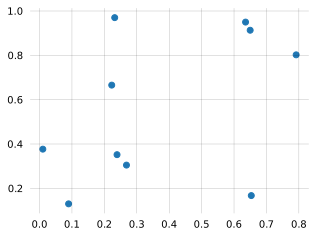

In [2]:
import matplotlib.pyplot as plt
plt.scatter(np.random.random(10), np.random.random(10)) ;

## Cell Magic

Importing `vscode` also makes the `%%monitor` cell magic available. This monitors CPU and memory while the notebook cell runs. Add `-p` to make the widget display mean/max usage when the cell completes.

In [3]:
%%monitor -p

# A simple computation
for i in range(10):
    result = sum(range(5_000_000))
    time.sleep(0.5)

You can customize the display width:

In [10]:
%%monitor -p -w 100

for i in range(4):
    x = sum(range(3_000_000))
    time.sleep(0.5)

Increase update frequency for smoother visualization:

In [13]:
%%monitor -i 0.25

# Updates 4 times per second
for i in range(8):
    result = sum(range(2_000_000))
    time.sleep(0.3)

## Context Manager: For Scripts

The context manager gives you explicit control over monitoring.
Perfect for Python scripts or when you want programmatic control.

In [21]:
from vscodenb import CPUMonitor

with CPUMonitor():
    # Your computation here
    for i in range(5):
        result = sum(range(4_000_000))
        time.sleep(0.5)

and with arguments:

In [23]:
with CPUMonitor(update_interval=0.3, width=100, persist=True):
    for i in range(5):
        result = sum(range(4_000_000))
        time.sleep(0.5)

## Decorator

Wrap any function with `@monitor` to automatically monitor its execution. Use it as function to pass keyword arguments:

In [39]:
from vscodenb import monitor

@monitor
def foo():
    for _ in range(5):
        sum(range(50_000_000))
        time.sleep(0.1)        
    
@monitor(update_interval=0.25)
def bar():
    for _ in range(5):
        sum(range(50_000_000))
        time.sleep(0.1)

@monitor(show_summary=True)
def baz():
    foo()
    bar()

baz()

## SLURM

`vscodenb` knows if the process runs in a SLURM job, in which case it `monitor` only monitors the allocated CPUs. You can run the code below locally and on SLURM to see the difference.

In [45]:
import os
from vscodenb import detect_compute_nodes

if 'SLURM_JOB_ID' in os.environ:
    print("Running on SLURM")
    print(f"  Job ID: {os.environ.get('SLURM_JOB_ID')}")
    print(f"  Nodes: {os.environ.get('SLURM_JOB_NUM_NODES', 'N/A')}")
    print(f"  CPUs per task: {os.environ.get('SLURM_CPUS_PER_TASK', 'N/A')}")
    print(f"  Node list: {os.environ.get('SLURM_JOB_NODELIST', 'N/A')}")
else:
    print("Running locally (not on SLURM)")

# Show detected nodes
print(f"\nDetected Resources:")
nodes = detect_compute_nodes()
for node in nodes:
    print(f"    {node.name}: {node.cpu_count} CPUs: {node.allocated_cpus}")


Running locally (not on SLURM)

Detected Resources:
    macbookpro: 10 CPUs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
